<h1 align='center' style='color:purple'>Clustering With K Means - Python Tutorial</h1>

## 3. The K-Means algorithm and its objective function

### 3.1 Steps

1. **Choose K** – the number of clusters.
2. **Initialise** K centroids $\mu_1, \dots, \mu_K$ (randomly picked points, or the smarter *k-means++* in scikit-learn).
3. **Assignment step** – give each point $x_i$ to the closest centroid using **Euclidean distance**:
$$d(x, \mu) = \sqrt{(x_1-\mu_1)^2 + (x_2-\mu_2)^2 + \dots}$$
$$c_i = \arg\min_{k}\; d(x_i, \mu_k)$$
4. **Update step** – move every centroid to the **mean** of the points assigned to it:
$$\mu_k = \frac{1}{|C_k|}\sum_{x_i \in C_k} x_i$$
5. **Repeat** steps 3–4 until the assignments (or centroids) stop changing — this is **convergence**.

### 3.2 What K-Means is minimising

K-Means minimises the **Within-Cluster Sum of Squares (WCSS)**, which scikit-learn calls **`inertia_`**:

$$\text{WCSS} = \sum_{k=1}^{K}\;\sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

* Each assignment step and each update step can only **decrease (or keep)** the WCSS ⇒ the algorithm is guaranteed to converge.
* But it converges to a **local** minimum, which depends on the starting centroids. That is why scikit-learn runs it several times (`n_init`) and keeps the best result.

## 4. Numerical worked example (by hand) ✍️

Let's cluster **7 points** into **K = 2** clusters completely by hand, and then let Python confirm every number.

| Point | x | y |
|---|---|---|
| A | 1.0 | 1.0 |
| B | 1.5 | 2.0 |
| C | 3.0 | 4.0 |
| D | 5.0 | 7.0 |
| E | 3.5 | 5.0 |
| F | 4.5 | 5.0 |
| G | 3.5 | 4.5 |

**Initial centroids** (chosen as two far-apart points): $\mu_1 = A = (1, 1)$ and $\mu_2 = D = (5, 7)$.

---

### 🔁 Iteration 1

**Assignment step.** Example calculation for point **B (1.5, 2)**:

$$d(B,\mu_1) = \sqrt{(1.5-1)^2 + (2-1)^2} = \sqrt{0.25+1} = \sqrt{1.25} = 1.118$$
$$d(B,\mu_2) = \sqrt{(1.5-5)^2 + (2-7)^2} = \sqrt{12.25+25} = \sqrt{37.25} = 6.103$$

$1.118 < 6.103$ ⇒ **B → Cluster 1**. Doing this for every point:

| Point | d to μ₁ (1, 1) | d to μ₂ (5, 7) | Assigned to |
|---|---|---|---|
| A | 0.000 | 7.211 | **C1** |
| B | 1.118 | 6.103 | **C1** |
| C | 3.606 | 3.606 | **C1** *(tie → first centroid)* |
| D | 7.211 | 0.000 | **C2** |
| E | 4.717 | 2.500 | **C2** |
| F | 5.315 | 2.062 | **C2** |
| G | 4.301 | 2.915 | **C2** |

> ⚠️ Point **C** is *exactly* the same distance from both centroids. By convention (and in NumPy's `argmin`) ties go to the **first** centroid.

**Update step.**

$$\mu_1 = \text{mean}(A,B,C) = \left(\tfrac{1+1.5+3}{3},\; \tfrac{1+2+4}{3}\right) = (1.833,\; 2.333)$$
$$\mu_2 = \text{mean}(D,E,F,G) = \left(\tfrac{5+3.5+4.5+3.5}{4},\; \tfrac{7+5+5+4.5}{4}\right) = (4.125,\; 5.375)$$

---

### 🔁 Iteration 2

| Point | d to μ₁ (1.833, 2.333) | d to μ₂ (4.125, 5.375) | Assigned to |
|---|---|---|---|
| A | 1.572 | 5.376 | C1 |
| B | 0.471 | 4.276 | C1 |
| C | 2.034 | **1.777** | **C2** ⬅ *changed!* |
| D | 5.640 | 1.846 | C2 |
| E | 3.145 | 0.729 | C2 |
| F | 3.771 | 0.530 | C2 |
| G | 2.734 | 1.075 | C2 |

Point **C** has moved to Cluster 2. **Update step:**

$$\mu_1 = \text{mean}(A,B) = (1.25,\; 1.5)$$
$$\mu_2 = \text{mean}(C,D,E,F,G) = \left(\tfrac{3+5+3.5+4.5+3.5}{5},\; \tfrac{4+7+5+5+4.5}{5}\right) = (3.9,\; 5.1)$$

---

### 🔁 Iteration 3

| Point | d to μ₁ (1.25, 1.5) | d to μ₂ (3.9, 5.1) | Assigned to |
|---|---|---|---|
| A | 0.559 | 5.022 | C1 |
| B | 0.559 | 3.920 | C1 |
| C | 3.052 | 1.421 | C2 |
| D | 6.657 | 2.195 | C2 |
| E | 4.161 | 0.412 | C2 |
| F | 4.776 | 0.608 | C2 |
| G | 3.750 | 0.721 | C2 |

No point changed cluster ⇒ the centroids stay at $(1.25, 1.5)$ and $(3.9, 5.1)$ ⇒ **converged ✅**

**Final clusters:** C1 = {A, B}, C2 = {C, D, E, F, G}

### 📉 WCSS at the end

$$\text{WCSS} = \underbrace{(0.25^2+0.5^2) + (0.25^2+0.5^2)}_{\text{C1: } A, B = 0.625} + \underbrace{(0.9^2+1.1^2) + (1.1^2+1.9^2) + (0.4^2+0.1^2) + (0.6^2+0.1^2) + (0.4^2+0.6^2)}_{\text{C2} = 7.9} = 8.525$$

WCSS went **33.25 → 11.23 → 8.525** across the iterations (computed with the centroids used in each assignment step) — it never increases.

Now let's check all of this with code 👇

## 5. Evaluation metrics for clustering 📏

Because clustering has **no ground-truth labels**, we can't use accuracy. Instead we use:

* **Internal metrics** – judge the clusters using only the data (compactness & separation).
* **External metrics** – compare to true labels, *only if* they happen to be available (e.g. for teaching datasets like Iris).

### 5.1 Internal metrics

| Metric | Formula / idea | Range | Better when | In sklearn |
|---|---|---|---|---|
| **WCSS / Inertia** | $\sum_k \sum_{x \in C_k}\lVert x-\mu_k\rVert^2$ — compactness | $[0, \infty)$ | **Lower** (but *always* falls as K grows) | `km.inertia_` |
| **Silhouette score** | $s(i) = \dfrac{b(i) - a(i)}{\max\{a(i), b(i)\}}$ averaged over all points | $[-1, 1]$ | **Higher** (≈1 great, ≈0 overlapping, <0 wrong cluster) | `silhouette_score` |


In the silhouette:
* $a(i)$ = average distance from point $i$ to the **other points in its own cluster** (how tight its cluster is),
* $b(i)$ = average distance from point $i$ to the points of the **nearest other cluster** (how far the neighbours are).

### 5.2 External metrics (need true labels)

| Metric | Range | Meaning |
|---|---|---|
| **Adjusted Rand Index (ARI)** | $[-1, 1]$ | 1 = perfect match with true labels, ≈0 = random labelling |
| **Normalized Mutual Information (NMI)** | $[0, 1]$ | 1 = clusters carry exactly the same information as the labels |

Both ignore the *names* of the clusters — cluster "0" vs "1" swapped still scores 1.0.

---

### ✍️ Hand calculation: silhouette of point A in the worked example

Final clusters: C1 = {A, B}, C2 = {C, D, E, F, G}.

**a(A)** – A's own cluster contains only B:
$$a(A) = d(A,B) = 1.118$$

**b(A)** – average distance from A to every point of C2:
$$b(A) = \frac{d(A,C)+d(A,D)+d(A,E)+d(A,F)+d(A,G)}{5} = \frac{3.606+7.211+4.717+5.315+4.301}{5} = \frac{25.150}{5} = 5.030$$

$$s(A) = \frac{5.030 - 1.118}{\max(1.118,\; 5.030)} = \frac{3.912}{5.030} = \mathbf{0.778}$$

A is **well inside** its cluster (close to 1). Let's verify, and compute all metrics for the worked example:

In [ ]:
from sklearn.cluster import KMeans
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
from sklearn.metrics import silhouette_score
import numpy as np
%matplotlib inline

# Load the data set

In [2]:
df=pd.read_csv("income.csv")
display(df.head(8))
display(df.describe())

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000
5,Gautam,39,155000
6,David,41,160000
7,Andrea,38,162000


,Age,Income($)
count,22.000000,22.000000
mean,34.818182,90431.818182
std,5.901060,43505.964412
min,26.000000,45000.000000
25%,29.000000,58500.000000
50%,36.500000,67500.000000
75%,39.750000,135250.000000
max,43.000000,162000.000000


# Plot the scater plot

Text(0, 0.5, 'Income($)')

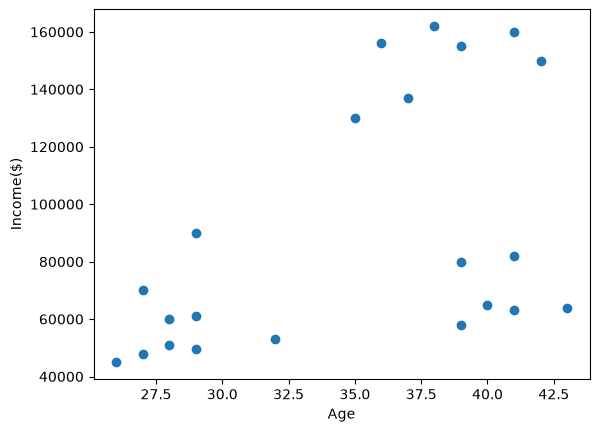

In [5]:
plt.scatter(df.Age,df["Income($)"])
plt.xlabel("Age")
plt.ylabel("Income($)")


By eye there are clearly **3 groups**: young/low income (bottom-left), older/high income (top-right) and older/medium income (bottom-right).

# Bulid and Train the model

In [15]:
km=KMeans(n_clusters=3)
y_predicted=km.fit_predict(df[["Age","Income($)"]])
y_predicted

array([2, 0, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2],
      dtype=int32)

# Assgin the cluster table to the samples 

In [16]:
df["cluster"] = y_predicted
df.head(10)

,Name,Age,Income($),cluster
0,Rob,27,70000,2
1,Michael,29,90000,0
2,Mohan,29,61000,2
3,Ismail,28,60000,2
4,Kory,42,150000,1
5,Gautam,39,155000,1
6,David,41,160000,1
7,Andrea,38,162000,1
8,Brad,36,156000,1
9,Angelina,35,130000,1


In [17]:
km.cluster_centers_

array([[3.63333333e+01, 8.40000000e+04],
       [3.82857143e+01, 1.50000000e+05],
       [3.24166667e+01, 5.72916667e+04]])

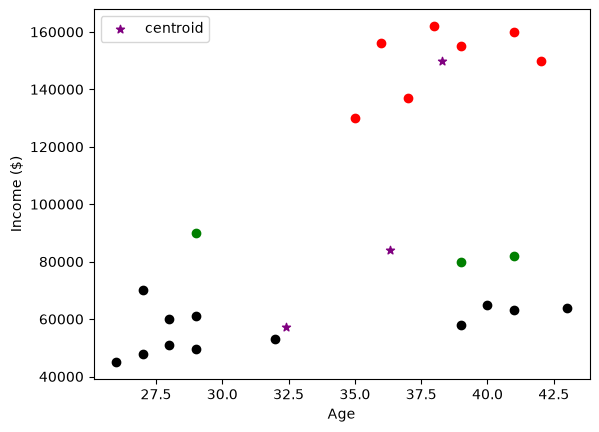

In [18]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.xlabel('Age')
plt.ylabel('Income ($)')
plt.legend()

The clusters are cut **horizontally by income only** — some young people end up with older people. Why?

<h4 style='color:purple'>Preprocessing using min max scaler</h4>


**Min–Max scaling** squeezes every feature into the range $[0, 1]$:

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

**Worked example** for Rob (Age 27, Income 70,000). Age range is 26 → 43, Income range is 45,000 → 162,000:

In [19]:
scaler = MinMaxScaler()

df[['Income($)', 'Age']] = scaler.fit_transform(
    df[['Income($)', 'Age']]
)

In [20]:
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,2
1,Michael,0.176471,0.384615,0
2,Mohan,0.176471,0.136752,2
3,Ismail,0.117647,0.128205,2
4,Kory,0.941176,0.897436,1


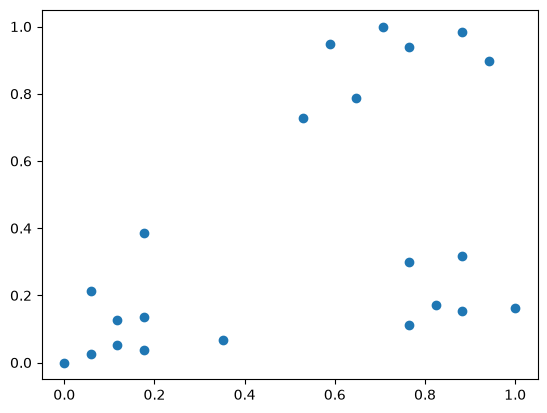

In [21]:
plt.scatter(df.Age,df['Income($)'])

In [22]:
km = KMeans(n_clusters=3)
y_predicted = km.fit_predict(df[['Age','Income($)']])
y_predicted

array([2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0],
      dtype=int32)

In [23]:
df['cluster']=y_predicted
df.head()

,Name,Age,Income($),cluster
0,Rob,0.058824,0.213675,2
1,Michael,0.176471,0.384615,2
2,Mohan,0.176471,0.136752,2
3,Ismail,0.117647,0.128205,2
4,Kory,0.941176,0.897436,1


In [24]:
km.cluster_centers_

array([[0.85294118, 0.2022792 ],
       [0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428]])

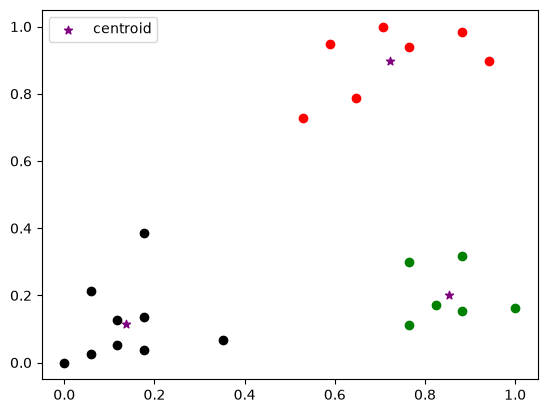

In [25]:
df1 = df[df.cluster==0]
df2 = df[df.cluster==1]
df3 = df[df.cluster==2]
plt.scatter(df1.Age,df1['Income($)'],color='green')
plt.scatter(df2.Age,df2['Income($)'],color='red')
plt.scatter(df3.Age,df3['Income($)'],color='black')
plt.scatter(km.cluster_centers_[:,0],km.cluster_centers_[:,1],color='purple',marker='*',label='centroid')
plt.legend()

<h4 style='color:purple'>Elbow Plot</h4>

[![Picture1.png](https://i.postimg.cc/k5xhZXvY/Picture1.png)](https://postimg.cc/3yxB0h62)

# SSE and silhouette scores



---



In [26]:
X = df[["Age","Income($)"]]
k_range = range(2,10)

sse,silhouette_scores = [],[]

for k in k_range:
    km = KMeans(n_clusters=k,random_state=42, n_init=10).fit(X)
    sse.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X,km.labels_))

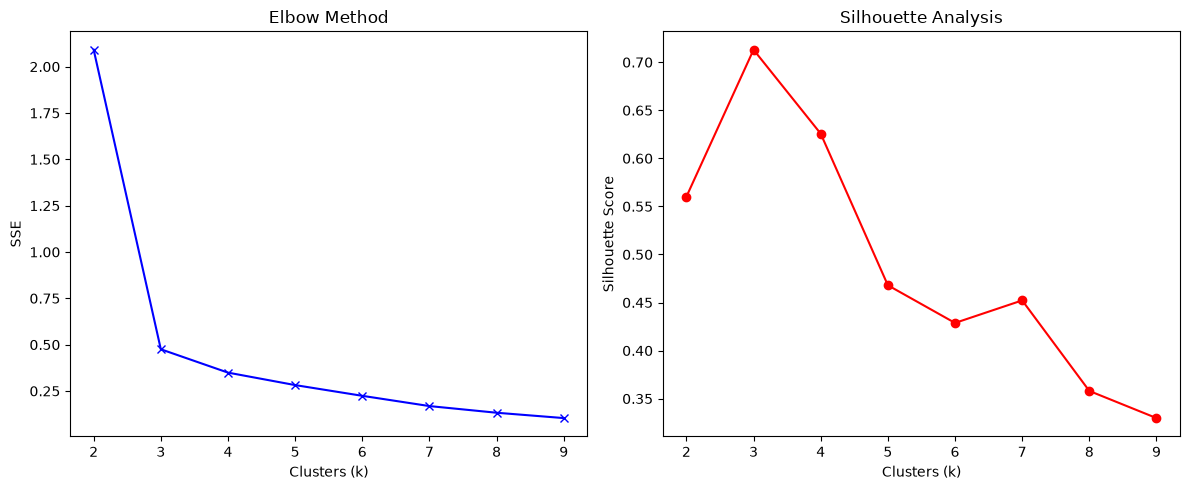

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(k_range, sse, 'bx-')
ax[0].set(title='Elbow Method', xlabel='Clusters (k)', ylabel='SSE')

ax[1].plot(k_range, silhouette_scores, 'ro-')
ax[1].set(title='Silhouette Analysis', xlabel='Clusters (k)', ylabel='Silhouette Score')

plt.tight_layout()
plt.show()

# load the dataset

In [28]:
df = pd.read_csv("income.csv")

print(df.head())

X = df[['Age', 'Income($)']].to_numpy(dtype=float)

      Name  Age  Income($)
0      Rob   27      70000
1  Michael   29      90000
2    Mohan   29      61000
3   Ismail   28      60000
4     Kory   42     150000


# Z-score normalization

In [29]:
# Z-score normalization
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

print("Standardized Data:\n", X_scaled[:5])

Standardized Data:
 [[-1.35605536 -0.48068427]
 [-1.00915747 -0.01015907]
 [-1.00915747 -0.69242061]
 [-1.18260641 -0.71594687]
 [ 1.24567876  1.40141653]]


# Define the custom K-Means algorithm

In [32]:
def kmeans(X, k, max_iters=100):
    np.random.seed(42)
    centroids = X[np.random.choice(len(X), k, replace=False)].copy()

    for _ in range(max_iters):
        labels = np.argmin(
            np.array([np.sum((X - c) ** 2, axis=1) for c in centroids]).T,
            axis=1
        )

        new_centroids = np.array([
            X[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i]
            for i in range(k)
        ])

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    labels = np.argmin(
        np.array([np.sum((X - c) ** 2, axis=1) for c in centroids]).T,
        axis=1
    )

    return centroids, labels


In [33]:
k = 3
centroids, labels = kmeans(X_scaled, k)

df['Cluster'] = labels

print(df.head())
print("Centroids:\n", centroids)

      Name  Age  Income($)  Cluster
0      Rob   27      70000        0
1  Michael   29      90000        0
2    Mohan   29      61000        0
3   Ismail   28      60000        0
4     Kory   42     150000        2
Centroids:
 [[-1.1247901  -0.74862223]
 [ 0.98550535 -0.51205261]
 [ 0.60143983  1.40141653]]


<h4 style='color:purple'>Exercise</h4>

## 📝 Lab Assignment: K-Means Clustering on the Wine Dataset — From Scratch vs. scikit-learn

### 🎯 Objective
Apply K-Means clustering to the **Wine dataset** in two ways:
1. a **from-scratch implementation**, written by you using only NumPy;
2. the **predefined `KMeans`** class from scikit-learn.

Evaluate both with standard clustering metrics and compare the results.

---

### 📂 Step 1 — Load the dataset
```python
from sklearn.datasets import load_wine
wine = load_wine()
X, y_true = wine.data, wine.target      # 178 wines, 13 chemical features, 3 cultivars
```
> ⚠️ **Do NOT use `y_true` for clustering.** Keep it aside and use it **only** for the external metrics (ARI, NMI) in Step 6.

---

### 🔍 Step 2 — Explore and preprocess
- Put `X` into a DataFrame with `wine.feature_names`. Show its shape, `head()` and `describe()`.
- Look at the feature ranges: for example, *proline* goes up to ~1680, while *hue* is around 1.
- Apply `StandardScaler`. **Explain in a markdown cell why scaling is necessary** for K-Means here.
- Use **PCA** to get 2 components (`PCA(n_components=2)`), **for plotting only**. Cluster on all 13 scaled features.

---

### 🛠️ Step 3 — K-Means from scratch
Write a function `kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42)` using **only NumPy**. It must:
1. **Initialise** K centroids by picking random data points.
2. **Assign** each point to its nearest centroid using Euclidean distance.
3. **Update** each centroid to the mean of the points assigned to it.
4. **Stop** when the centroids no longer move (or `max_iters` is reached).
5. Repeat the whole run `n_init` times and keep the run with the **lowest WCSS**.
6. **Return** `centroids`, `labels`, `wcss` and the number of iterations.

Also write your own function to compute **WCSS**:
$$\text{WCSS} = \sum_{k=1}^{K}\sum_{x_i \in C_k}\lVert x_i-\mu_k\rVert^2$$

⭐ **Bonus:** implement the **silhouette score from scratch** and check that it matches `sklearn.metrics.silhouette_score`.

---

### 📦 Step 4 — K-Means with scikit-learn
```python
from sklearn.cluster import KMeans
km = KMeans(n_clusters=k, n_init=10, random_state=42)
labels_sk = km.fit_predict(X_scaled)
```
Report `km.cluster_centers_`, `km.inertia_` and `km.n_iter_`.

---

### 📈 Step 5 — Choose the optimal K
For **K = 2 to 10**, using **both** implementations:
- Plot the **Elbow curve** (WCSS vs K).
- Plot the **Silhouette score vs K**.
- State your chosen K and explain why. Does it match the 3 true cultivars?

---

### 📏 Step 6 — Evaluate both models
Fill in this table for your chosen K:

| Metric | Type | Better | Scratch | scikit-learn |
|---|---|---|---|---|
| WCSS / Inertia | Internal | ↓ Lower | | |
| Silhouette score | Internal | ↑ Higher (max 1) | | |

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

# Load the Wine dataset
wine = load_wine()

# Separate input features and actual labels
X = wine.data
y_true = wine.target

print("Dataset loaded successfully!")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of cultivars:", len(np.unique(y_true)))

Dataset loaded successfully!
Number of samples: 178
Number of features: 13
Number of cultivars: 3


In [2]:
# Convert the dataset into a Pandas DataFrame
df = pd.DataFrame(X, columns=wine.feature_names)

# Display dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five rows
display(df.head())

# Display statistical summary
display(df.describe())

Dataset Shape: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [3]:
# Display minimum and maximum values of every feature
print("Feature Ranges:\n")

for column in df.columns:
    print(column, ":", df[column].min(), "to", df[column].max())

Feature Ranges:

alcohol : 11.03 to 14.83
malic_acid : 0.74 to 5.8
ash : 1.36 to 3.23
alcalinity_of_ash : 10.6 to 30.0
magnesium : 70.0 to 162.0
total_phenols : 0.98 to 3.88
flavanoids : 0.34 to 5.08
nonflavanoid_phenols : 0.13 to 0.66
proanthocyanins : 0.41 to 3.58
color_intensity : 1.28 to 13.0
hue : 0.48 to 1.71
od280/od315_of_diluted_wines : 1.27 to 4.0
proline : 278.0 to 1680.0


In [4]:
# Apply StandardScaler to standardize all 13 features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# Display the first five standardized samples
print("Standardized Data:\n")
print(X_scaled[:5])

# Check the mean and standard deviation
print("\nFeature Means:\n", X_scaled.mean(axis=0))
print("\nFeature Standard Deviations:\n", X_scaled.std(axis=0))

Standardized Data:

[[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]

Feature Means:
 [ 7.84141790e-15  2.44498554e-16 -4.05917497e-15 -7.11041712e-17
 -2.49488320e-17 -1.95536471e-16  9.44313292e-16 -4.17892936e-16
 -1.54059038e-15 -

Standardization is necessary because the Wine dataset contains features with different measurement scales. For example, proline has values much larger than hue. K-Means uses Euclidean distance to calculate the similarity between data points. Features with larger numerical ranges can dominate the distance calculation. StandardScaler transforms the features to have approximately zero mean and unit standard deviation, ensuring that all features contribute more equally to clustering.

PCA Shape: (178, 2)


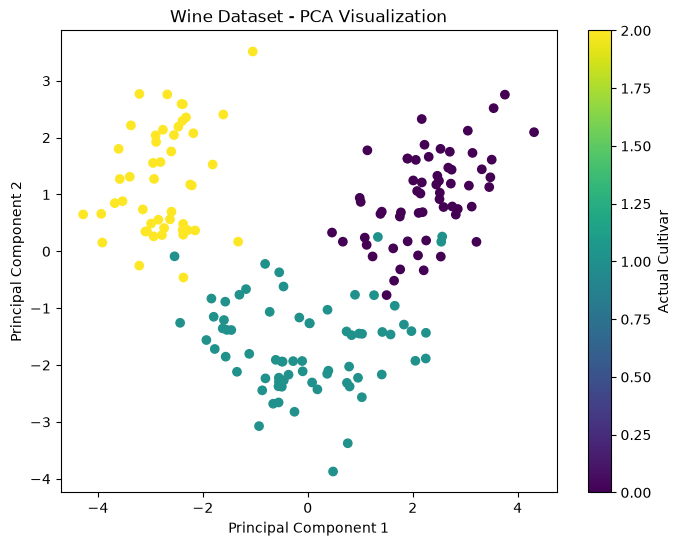

In [5]:
# Reduce the 13 standardized features into 2 principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Display the reduced dataset
print("PCA Shape:", X_pca.shape)

# Plot the two principal components using actual labels for visualization
plt.figure(figsize=(8, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='viridis')

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wine Dataset - PCA Visualization")
plt.colorbar(label="Actual Cultivar")

plt.show()

In [6]:
# Function to calculate Within-Cluster Sum of Squares (WCSS)
def calculate_wcss(X, centroids, labels):
    wcss = 0

    # Calculate squared distances between points and their assigned centroids
    for i in range(len(centroids)):
        cluster_points = X[labels == i]

        if len(cluster_points) > 0:
            distances = np.sum((cluster_points - centroids[i]) ** 2)
            wcss += distances

    return wcss

In [7]:
# Implement K-Means clustering using only NumPy
def kmeans_scratch(X, k, max_iters=100, n_init=10, seed=42):

    best_wcss = float('inf')
    best_centroids = None
    best_labels = None
    best_iterations = 0

    # Repeat the algorithm multiple times with different initial centroids
    for run in range(n_init):

        rng = np.random.default_rng(seed + run)

        # Randomly select K data points as initial centroids
        centroids = X[rng.choice(len(X), k, replace=False)].copy()

        for iteration in range(max_iters):

            # Calculate Euclidean distances from every point to every centroid
            distances = np.array([
                np.sum((X - centroid) ** 2, axis=1)
                for centroid in centroids
            ]).T

            # Assign each point to its nearest centroid
            labels = np.argmin(distances, axis=1)

            # Calculate new centroids using the mean of assigned points
            new_centroids = np.array([
                X[labels == i].mean(axis=0)
                if np.any(labels == i)
                else centroids[i]
                for i in range(k)
            ])

            # Stop if centroids no longer move
            if np.allclose(centroids, new_centroids):
                centroids = new_centroids
                break

            centroids = new_centroids

        # Reassign points using the final centroids
        distances = np.array([
            np.sum((X - centroid) ** 2, axis=1)
            for centroid in centroids
        ]).T

        labels = np.argmin(distances, axis=1)

        # Calculate WCSS for the current run
        current_wcss = calculate_wcss(X, centroids, labels)

        # Store the best clustering result
        if current_wcss < best_wcss:
            best_wcss = current_wcss
            best_centroids = centroids.copy()
            best_labels = labels.copy()
            best_iterations = iteration + 1

    return best_centroids, best_labels, best_wcss, best_iterations

In [8]:
# Set the number of clusters
k = 3

# Execute the custom K-Means algorithm
centroids_scratch, labels_scratch, wcss_scratch, iterations_scratch = kmeans_scratch(
    X_scaled, k
)

# Display the results
print("Scratch K-Means Results")
print("\nCentroids:\n", centroids_scratch)
print("\nWCSS:", wcss_scratch)
print("\nNumber of Iterations:", iterations_scratch)
print("\nCluster Labels:\n", labels_scratch)

Scratch K-Means Results

Centroids:
 [[-0.92607185 -0.39404154 -0.49451676  0.17060184 -0.49171185 -0.07598265
   0.02081257 -0.03353357  0.0582655  -0.90191402  0.46180361  0.27076419
  -0.75384618]
 [ 0.83523208 -0.30380968  0.36470604 -0.61019129  0.5775868   0.88523736
   0.97781956 -0.56208965  0.58028658  0.17106348  0.47398365  0.77924711
   1.12518529]
 [ 0.16490746  0.87154706  0.18689833  0.52436746 -0.07547277 -0.97933029
  -1.21524764  0.72606354 -0.77970639  0.94153874 -1.16478865 -1.29241163
  -0.40708796]]

WCSS: 1277.9284888446423

Number of Iterations: 3

Cluster Labels:
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 2 0 0 0 0 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 2 0 0 1 0 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


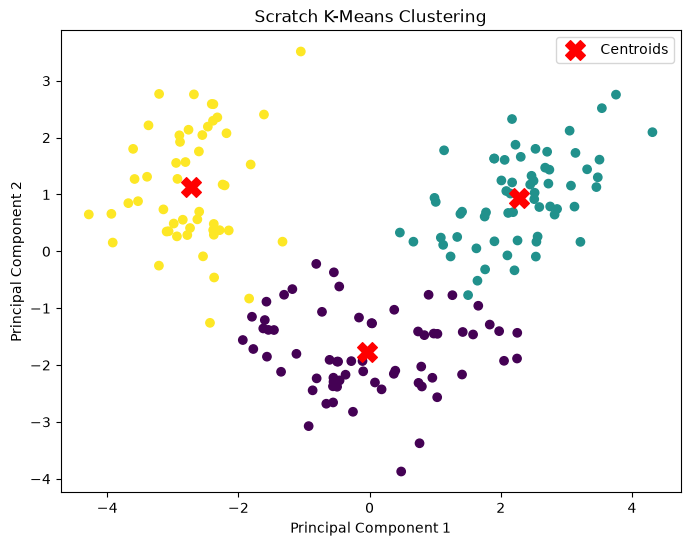

In [9]:
# Visualize the scratch K-Means clusters using PCA components
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_scratch,
    cmap='viridis'
)

# Plot the cluster centroids after transforming them into PCA space
centroids_pca = pca.transform(centroids_scratch)

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Scratch K-Means Clustering")
plt.legend()

plt.show()

In [10]:
# Create the K-Means model with 3 clusters
km = KMeans(n_clusters=3, n_init=10, random_state=42)

# Train the model and predict cluster labels
labels_sk = km.fit_predict(X_scaled)

# Display model results
print("Scikit-learn K-Means Results")

print("\nCluster Centers:\n", km.cluster_centers_)
print("\nWCSS / Inertia:", km.inertia_)
print("\nNumber of Iterations:", km.n_iter_)
print("\nCluster Labels:\n", labels_sk)

Scikit-learn K-Means Results

Cluster Centers:
 [[-0.92607185 -0.39404154 -0.49451676  0.17060184 -0.49171185 -0.07598265
   0.02081257 -0.03353357  0.0582655  -0.90191402  0.46180361  0.27076419
  -0.75384618]
 [ 0.16490746  0.87154706  0.18689833  0.52436746 -0.07547277 -0.97933029
  -1.21524764  0.72606354 -0.77970639  0.94153874 -1.16478865 -1.29241163
  -0.40708796]
 [ 0.83523208 -0.30380968  0.36470604 -0.61019129  0.5775868   0.88523736
   0.97781956 -0.56208965  0.58028658  0.17106348  0.47398365  0.77924711
   1.12518529]]

WCSS / Inertia: 1277.928488844642

Number of Iterations: 7

Cluster Labels:
 [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


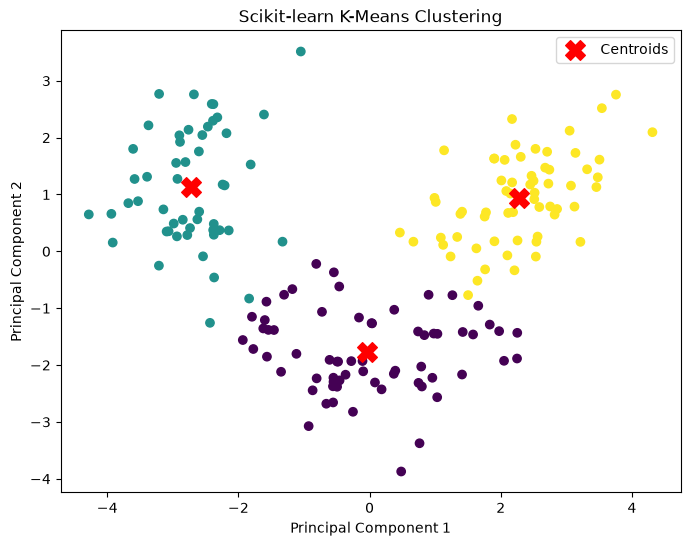

In [11]:
# Plot the clusters using PCA for visualization
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels_sk,
    cmap='viridis'
)

# Transform cluster centers into PCA space
centers_pca = pca.transform(km.cluster_centers_)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Scikit-learn K-Means Clustering")
plt.legend()

plt.show()

In [12]:
# Store WCSS and silhouette scores for different values of K
k_range = range(2, 11)

wcss_scratch_list = []
wcss_sk_list = []

silhouette_scratch_list = []
silhouette_sk_list = []

# Evaluate both implementations for K = 2 to 10
for k in k_range:

    # Run scratch K-Means
    centroids, labels, wcss, iterations = kmeans_scratch(
        X_scaled, k, n_init=10, seed=42
    )

    wcss_scratch_list.append(wcss)

    # Calculate silhouette score using sklearn for both clusterings
    silhouette_scratch_list.append(
        silhouette_score(X_scaled, labels)
    )

    # Run scikit-learn K-Means
    km = KMeans(n_clusters=k, n_init=10, random_state=42)

    labels_sk = km.fit_predict(X_scaled)

    wcss_sk_list.append(km.inertia_)

    silhouette_sk_list.append(
        silhouette_score(X_scaled, labels_sk)
    )

print("Evaluation completed for K = 2 to 10")

Evaluation completed for K = 2 to 10


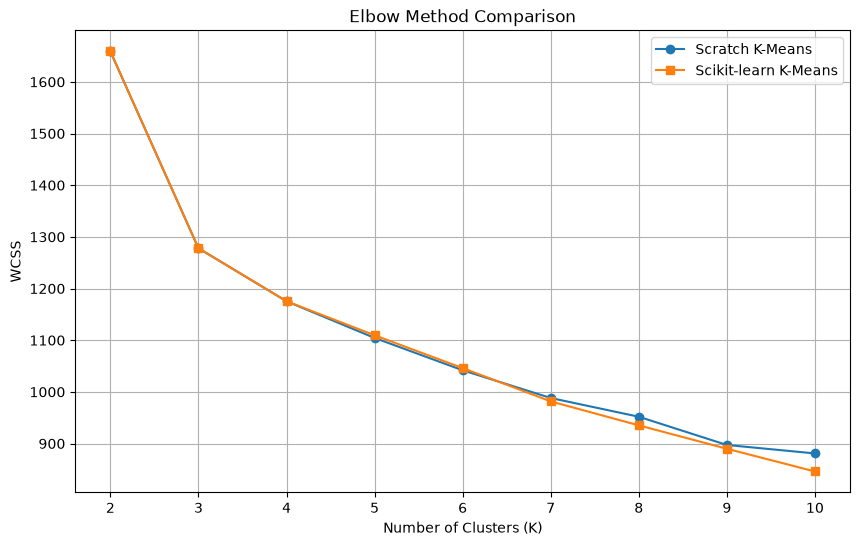

In [13]:
# Compare WCSS values of both implementations
plt.figure(figsize=(10, 6))

plt.plot(
    k_range,
    wcss_scratch_list,
    marker='o',
    label='Scratch K-Means'
)

plt.plot(
    k_range,
    wcss_sk_list,
    marker='s',
    label='Scikit-learn K-Means'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method Comparison")

plt.xticks(list(k_range))
plt.legend()
plt.grid(True)

plt.show()

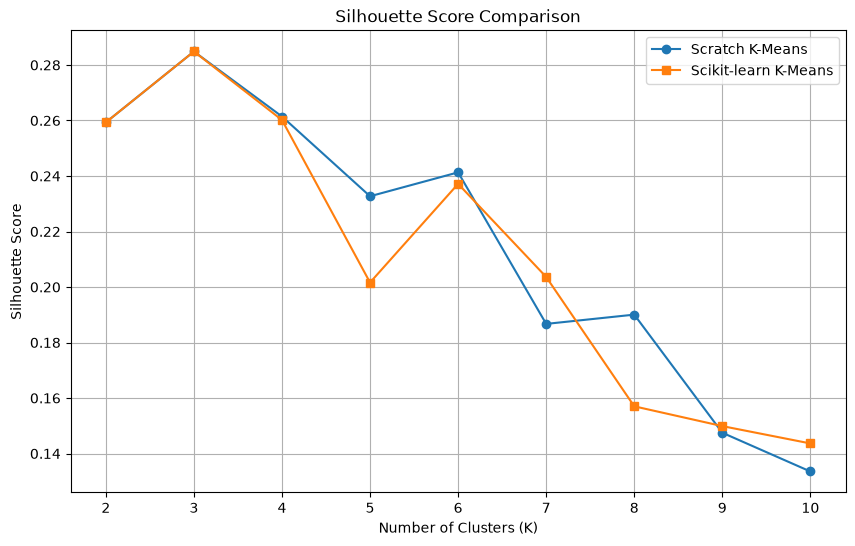

In [14]:
# Compare silhouette scores of both implementations
plt.figure(figsize=(10, 6))

plt.plot(
    k_range,
    silhouette_scratch_list,
    marker='o',
    label='Scratch K-Means'
)

plt.plot(
    k_range,
    silhouette_sk_list,
    marker='s',
    label='Scikit-learn K-Means'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")

plt.xticks(list(k_range))
plt.legend()
plt.grid(True)

plt.show()

In [15]:
# Display WCSS and silhouette scores for every K
comparison_df = pd.DataFrame({
    'K': list(k_range),
    'Scratch WCSS': wcss_scratch_list,
    'Sklearn WCSS': wcss_sk_list,
    'Scratch Silhouette': silhouette_scratch_list,
    'Sklearn Silhouette': silhouette_sk_list
})

display(comparison_df)

,K,Scratch WCSS,Sklearn WCSS,Scratch Silhouette,Sklearn Silhouette
0,2,1658.758852,1658.758852,0.259317,0.259317
1,3,1277.928489,1277.928489,0.284859,0.284859
2,4,1175.378999,1175.428333,0.261435,0.260170
3,5,1104.378203,1109.512739,0.232703,0.201619
4,6,1041.801546,1046.002333,0.241313,0.237167
5,7,988.129646,981.595233,0.186712,0.203628
6,8,951.857155,935.201211,0.190048,0.157014
7,9,897.225072,889.892911,0.147494,0.149882
8,10,880.843134,845.895237,0.133531,0.143638


In [16]:
# Find the K value with the highest silhouette score
best_k_scratch = list(k_range)[np.argmax(silhouette_scratch_list)]

best_k_sk = list(k_range)[np.argmax(silhouette_sk_list)]

print("Best K using Scratch K-Means:", best_k_scratch)
print("Best K using Scikit-learn:", best_k_sk)

# Display the selected number of clusters
print("\nActual number of cultivars in Wine dataset:", len(np.unique(y_true)))

Best K using Scratch K-Means: 3
Best K using Scikit-learn: 3

Actual number of cultivars in Wine dataset: 3


The Elbow Method helps determine the optimal number of clusters by observing the point where the decrease in WCSS starts becoming less significant. The Silhouette Score measures how well-separated and compact the clusters are. A higher silhouette score indicates better clustering.

The optimal value of K should be selected by considering both the Elbow curve and the Silhouette score. The Wine dataset contains three actual cultivars, so K = 3 is a meaningful value to examine. However, the optimal K obtained from clustering metrics may differ from the actual number of cultivars.

In [17]:
# Set the chosen number of clusters
k = 3

# Run scratch K-Means
centroids_scratch, labels_scratch, wcss_scratch, iterations_scratch = kmeans_scratch(
    X_scaled, k, n_init=10, seed=42
)

# Run scikit-learn K-Means
km = KMeans(n_clusters=k, n_init=10, random_state=42)

labels_sk = km.fit_predict(X_scaled)

# Calculate silhouette scores
silhouette_scratch = silhouette_score(X_scaled, labels_scratch)
silhouette_sk = silhouette_score(X_scaled, labels_sk)

# Calculate external evaluation metrics using actual labels
ari_scratch = adjusted_rand_score(y_true, labels_scratch)
ari_sk = adjusted_rand_score(y_true, labels_sk)

nmi_scratch = normalized_mutual_info_score(y_true, labels_scratch)
nmi_sk = normalized_mutual_info_score(y_true, labels_sk)

# Display the results
print("SCRATCH K-MEANS")
print("WCSS:", wcss_scratch)
print("Silhouette Score:", silhouette_scratch)
print("ARI:", ari_scratch)
print("NMI:", nmi_scratch)

print("\nSCIKIT-LEARN K-MEANS")
print("WCSS:", km.inertia_)
print("Silhouette Score:", silhouette_sk)
print("ARI:", ari_sk)
print("NMI:", nmi_sk)

SCRATCH K-MEANS
WCSS: 1277.9284888446423
Silhouette Score: 0.2848589191898987
ARI: 0.8974949815093207
NMI: 0.8758935341223069

SCIKIT-LEARN K-MEANS
WCSS: 1277.928488844642
Silhouette Score: 0.2848589191898987
ARI: 0.8974949815093207
NMI: 0.8758935341223069


In [18]:
# Create a comparison table for both clustering models
results = pd.DataFrame({
    'Metric': ['WCSS / Inertia', 'Silhouette Score', 'Adjusted Rand Index (ARI)', 'Normalized Mutual Information (NMI)'],
    'Type': ['Internal', 'Internal', 'External', 'External'],
    'Better': ['Lower', 'Higher', 'Higher', 'Higher'],
    'Scratch': [wcss_scratch, silhouette_scratch, ari_scratch, nmi_scratch],
    'Scikit-learn': [km.inertia_, silhouette_sk, ari_sk, nmi_sk]
})

display(results)

,Metric,Type,Better,Scratch,Scikit-learn
0,WCSS / Inertia,Internal,Lower,1277.928489,1277.928489
1,Silhouette Score,Internal,Higher,0.284859,0.284859
2,Adjusted Rand Index (ARI),External,Higher,0.897495,0.897495
3,Normalized Mutual Information (NMI),External,Higher,0.875894,0.875894


- WCSS / Inertia: Measures the sum of squared distances between data points and their assigned cluster centroids. Lower values indicate more compact clusters.
- Silhouette Score: Measures cluster compactness and separation. Values closer to 1 indicate better-defined clusters.
- Adjusted Rand Index (ARI): Measures the similarity between predicted clusters and actual cultivar labels, adjusted for random agreement.
- Normalized Mutual Information (NMI): Measures the agreement between predicted clusters and actual cultivar labels. Higher values indicate better agreement.
The Scratch K-Means and Scikit-learn K-Means implementations are compared using internal and external evaluation metrics. Internal metrics evaluate clustering quality without actual labels, while external metrics compare the predicted clusters against the actual cultivar labels.

Conclusion:

The K-Means clustering algorithm was implemented successfully using two approaches: a custom implementation using NumPy and the predefined KMeans class from scikit-learn.

The Wine dataset was standardized using StandardScaler to ensure that all 13 chemical features contribute appropriately to distance calculations. PCA was used to visualize the clustering results in two dimensions.

The Elbow Method and Silhouette Score were used to evaluate different cluster counts from K = 2 to K = 10. Both implementations were compared using WCSS, Silhouette Score, Adjusted Rand Index and Normalized Mutual Information.